<a href="https://colab.research.google.com/github/sofilukash/classification_algorithms_scikit-learn_lab1/blob/main/UAV_FANET_classification.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Лабораторна: класифікація стану FANET-мережі БпЛА під час катастроф
**Датасет:** Secure and Resilient UAV Communication Dataset (Kaggle, researchailabs)  
**Задача:** за параметрами вузла/каналу зв'язку БпЛА передбачити `Network_Status` (Normal / Degraded / Critical).  
**Моделі:** kNN, Decision Tree, SVM, Random Forest, AdaBoost.

In [2]:
!pip -q install kagglehub
import glob, os, warnings
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
import kagglehub
from sklearn.model_selection import train_test_split, GridSearchCV, cross_val_score, StratifiedKFold
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier, AdaBoostClassifier
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score, f1_score, ConfusionMatrixDisplay
warnings.filterwarnings('ignore')
sns.set_theme(style='whitegrid')
RANDOM_STATE = 42

## 1. Завантаження та первинний аналіз

In [3]:
path = kagglehub.dataset_download('researchailabs/secure-and-resilient-uav-communication-dataset')
print('Папка:', path)
csv_files = glob.glob(os.path.join(path, '**', '*.csv'), recursive=True)
print(csv_files)
df = pd.read_csv(csv_files[0])
df.head()

100%|██████████| 683k/683k [00:00<00:00, 19.7MB/s]

Extracting files...
Папка: /root/.cache/kagglehub/datasets/researchailabs/secure-and-resilient-uav-communication-dataset/versions/1
['/root/.cache/kagglehub/datasets/researchailabs/secure-and-resilient-uav-communication-dataset/versions/1/FANET Disaster Dataset.csv']


,UAV_ID,Role,X,Y,Z,Velocity,Direction,Energy_Level,Neighbor_Count,Link_Stability,...,Throughput,Packet_Delivery_Ratio,Signal_Strength,Disaster_Type,Obstacle_Density,Weather_Condition,Attack_Type,Recovery_Time,Route_Change_Count,Network_Status
0,52,Sensor,25.896070,524.585579,231.419533,29.899351,167.173833,38.415590,1,0.624923,...,82.468916,0.955169,-94.312313,Cyclone,0.359033,Smoke,Replay,29.051812,14,Degraded
1,93,Sensor,285.211745,222.748770,68.653310,11.018614,229.804488,65.064156,14,0.460945,...,53.653340,0.636328,-47.406575,Cyclone,0.405394,Windy,Jamming,22.047519,3,Critical
2,15,Sensor,553.969950,337.656169,150.723903,27.511250,316.610347,73.974680,11,0.690067,...,46.723480,0.679186,-92.428641,Earthquake,0.246429,Windy,Sybil,44.297353,14,Critical
3,72,Relay,1.601188,490.350441,50.638397,7.362888,273.693110,10.933315,4,0.477680,...,57.621276,0.925962,-61.124781,Cyclone,0.571353,Windy,NaN,12.903208,13,Degraded
4,61,Sensor,283.219084,316.885552,177.801686,22.745005,327.223118,13.080558,9,0.957999,...,36.329833,0.745412,-76.678259,Earthquake,0.435168,Clear,NaN,16.557381,14,Critical


Розмір датасета: (5000, 22)
Колонки: ['UAV_ID', 'Role', 'X', 'Y', 'Z', 'Velocity', 'Direction', 'Energy_Level', 'Neighbor_Count', 'Link_Stability', 'Topology_Change_Rate', 'Latency', 'Throughput', 'Packet_Delivery_Ratio', 'Signal_Strength', 'Disaster_Type', 'Obstacle_Density', 'Weather_Condition', 'Attack_Type', 'Recovery_Time', 'Route_Change_Count', 'Network_Status']

Типи даних:
UAV_ID                     int64
Role                      object
X                        float64
Y                        float64
Z                        float64
Velocity                 float64
Direction                float64
Energy_Level             float64
Neighbor_Count             int64
Link_Stability           float64
Topology_Change_Rate     float64
Latency                  float64
Throughput               float64
Packet_Delivery_Ratio    float64
Signal_Strength          float64
Disaster_Type             object
Obstacle_Density         float64
Weather_Condition         object
Attack_Type           

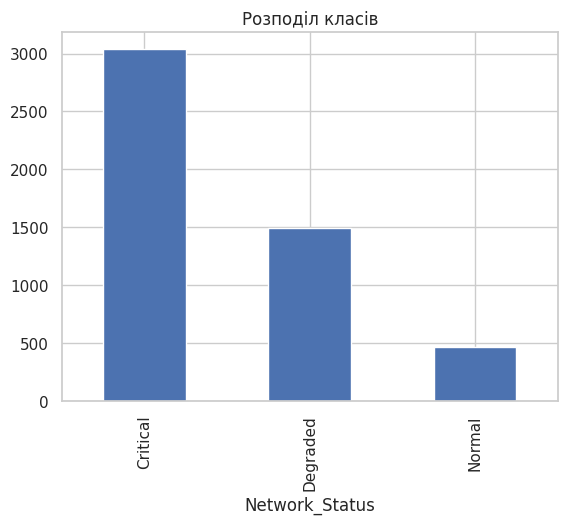

,count,mean,std,min,25%,50%,75%,max
UAV_ID,5000.0,49.398200,28.677471,1.000000,25.000000,49.000000,74.000000,99.000000
X,5000.0,500.751170,287.555057,0.185195,259.995665,501.766596,747.994518,999.751563
Y,5000.0,501.933341,286.677425,0.118645,255.845246,502.943692,744.324116,999.892667
Z,5000.0,173.868818,72.443035,50.002324,110.363980,173.647367,236.884450,299.923708
Velocity,5000.0,17.570787,7.223918,5.005035,11.374398,17.535122,23.822680,29.997277
Direction,5000.0,182.518053,103.250292,0.007386,95.012152,184.601914,272.024518,359.990592
Energy_Level,5000.0,54.416820,26.024749,10.009214,31.933907,54.356301,76.959705,99.990972
Neighbor_Count,5000.0,7.526000,4.029463,1.000000,4.000000,8.000000,11.000000,14.000000
Link_Stability,5000.0,0.648078,0.203389,0.300012,0.472151,0.643398,0.827359,0.999981
Topology_Change_Rate,5000.0,0.546745,0.260964,0.100094,0.315583,0.544638,0.776854,0.999961


In [4]:
TARGET = 'Network_Status'
print('Розмір датасета:', df.shape)
print('Колонки:', list(df.columns))
print('\nТипи даних:'); print(df.dtypes)
print('\nЦільова змінна:', TARGET)
print('Розподіл за класами:'); print(df[TARGET].value_counts()); print(df[TARGET].value_counts(normalize=True).round(3))
df[TARGET].value_counts().plot(kind='bar', title='Розподіл класів'); plt.show()
df.describe().T

**Ознаки:** координати (X, Y, Z), швидкість, напрям, енергія, кількість сусідів, стабільність лінку, швидкість зміни топології, затримка, пропускна здатність, PDR, сила сигналу, щільність перешкод, час відновлення, кількість змін маршруту + категоріальні (Role, Disaster_Type, Weather_Condition, Attack_Type).  
**Ціль:** `Network_Status`.

## 2. Попередня обробка

In [5]:
print('Пропуски:'); print(df.isna().sum()[df.isna().sum() > 0] if df.isna().sum().sum() else 'немає')
print('Дублікатів:', df.duplicated().sum())
print('Унікальних UAV_ID:', df['UAV_ID'].nunique(), 'з', len(df))
cat_cols = df.select_dtypes(include='object').columns.drop(TARGET).tolist()
print('Категоріальні:', cat_cols)
for c in cat_cols: print(c, df[c].unique())

Пропуски:
Attack_Type    988
dtype: int64
Дублікатів: 0
Унікальних UAV_ID: 99 з 5000
Категоріальні: ['Role', 'Disaster_Type', 'Weather_Condition', 'Attack_Type']
Role ['Sensor' 'Relay' 'Leader']
Disaster_Type ['Cyclone' 'Earthquake' 'Wildfire' 'Flood']
Weather_Condition ['Smoke' 'Windy' 'Clear' 'Rain']
Attack_Type ['Replay' 'Jamming' 'Sybil' nan 'Blackhole']


In [6]:
data = df.copy()
# 1) пропуски: числові -> медіана, категоріальні -> мода (якщо вони є)
for c in data.columns.drop(TARGET):
    if data[c].isna().any():
        data[c] = data[c].fillna(data[c].median() if data[c].dtype != 'object' else data[c].mode()[0])
data = data.dropna(subset=[TARGET]).drop_duplicates()
# 2) UAV_ID - це ідентифікатор, а не фізична характеристика -> видаляємо (інакше модель вчитиме шум)
data = data.drop(columns=['UAV_ID'])
# 3) категоріальні -> one-hot (номінальні, порядку між ними немає)
data = pd.get_dummies(data, columns=cat_cols, drop_first=False, dtype=int)
# 4) цільова змінна -> числа
le = LabelEncoder()
y = le.fit_transform(data[TARGET])
X = data.drop(columns=[TARGET])
print('Класи:', dict(zip(le.classes_, le.transform(le.classes_))))
print('X shape:', X.shape)

Класи: {'Critical': np.int64(0), 'Degraded': np.int64(1), 'Normal': np.int64(2)}
X shape: (5000, 31)


**Рішення:** `UAV_ID` видалено (ідентифікатор); пропуски заповнюються медіаною/модою (якщо є); категоріальні ознаки кодуються One-Hot, бо порядку між категоріями немає; ціль кодується LabelEncoder.

## 3. EDA

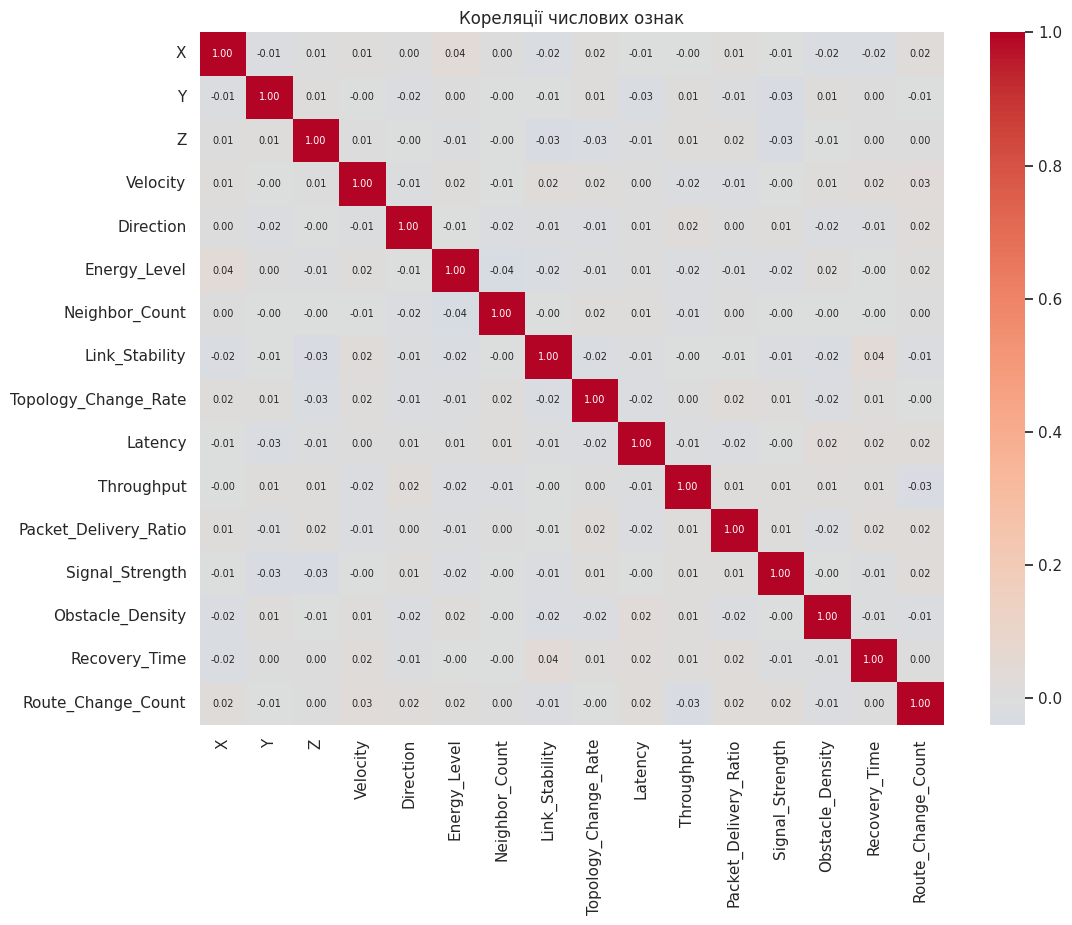

In [7]:
num_cols = df.select_dtypes(include='number').columns.drop('UAV_ID').tolist()
plt.figure(figsize=(12, 9))
sns.heatmap(df[num_cols].corr(), annot=True, fmt='.2f', cmap='coolwarm', center=0, annot_kws={'size': 7})
plt.title('Кореляції числових ознак'); plt.show()

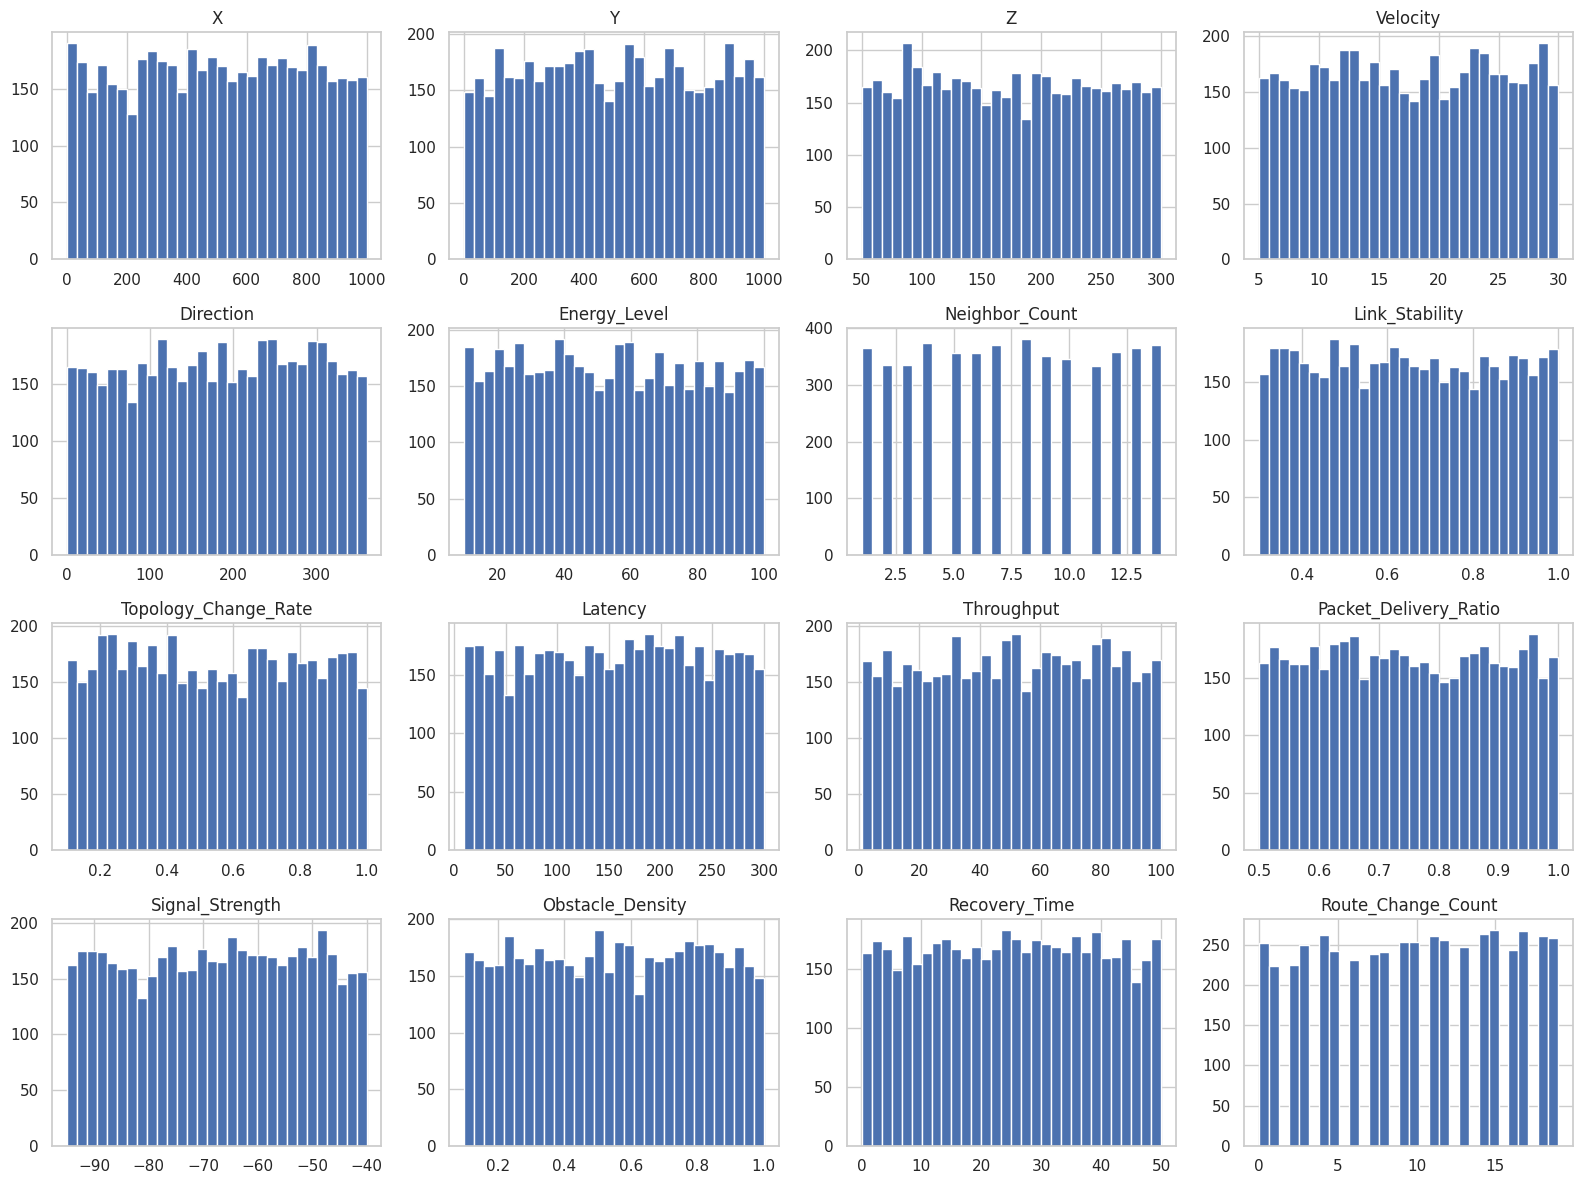

In [8]:
df[num_cols].hist(bins=30, figsize=(16, 12)); plt.tight_layout(); plt.show()

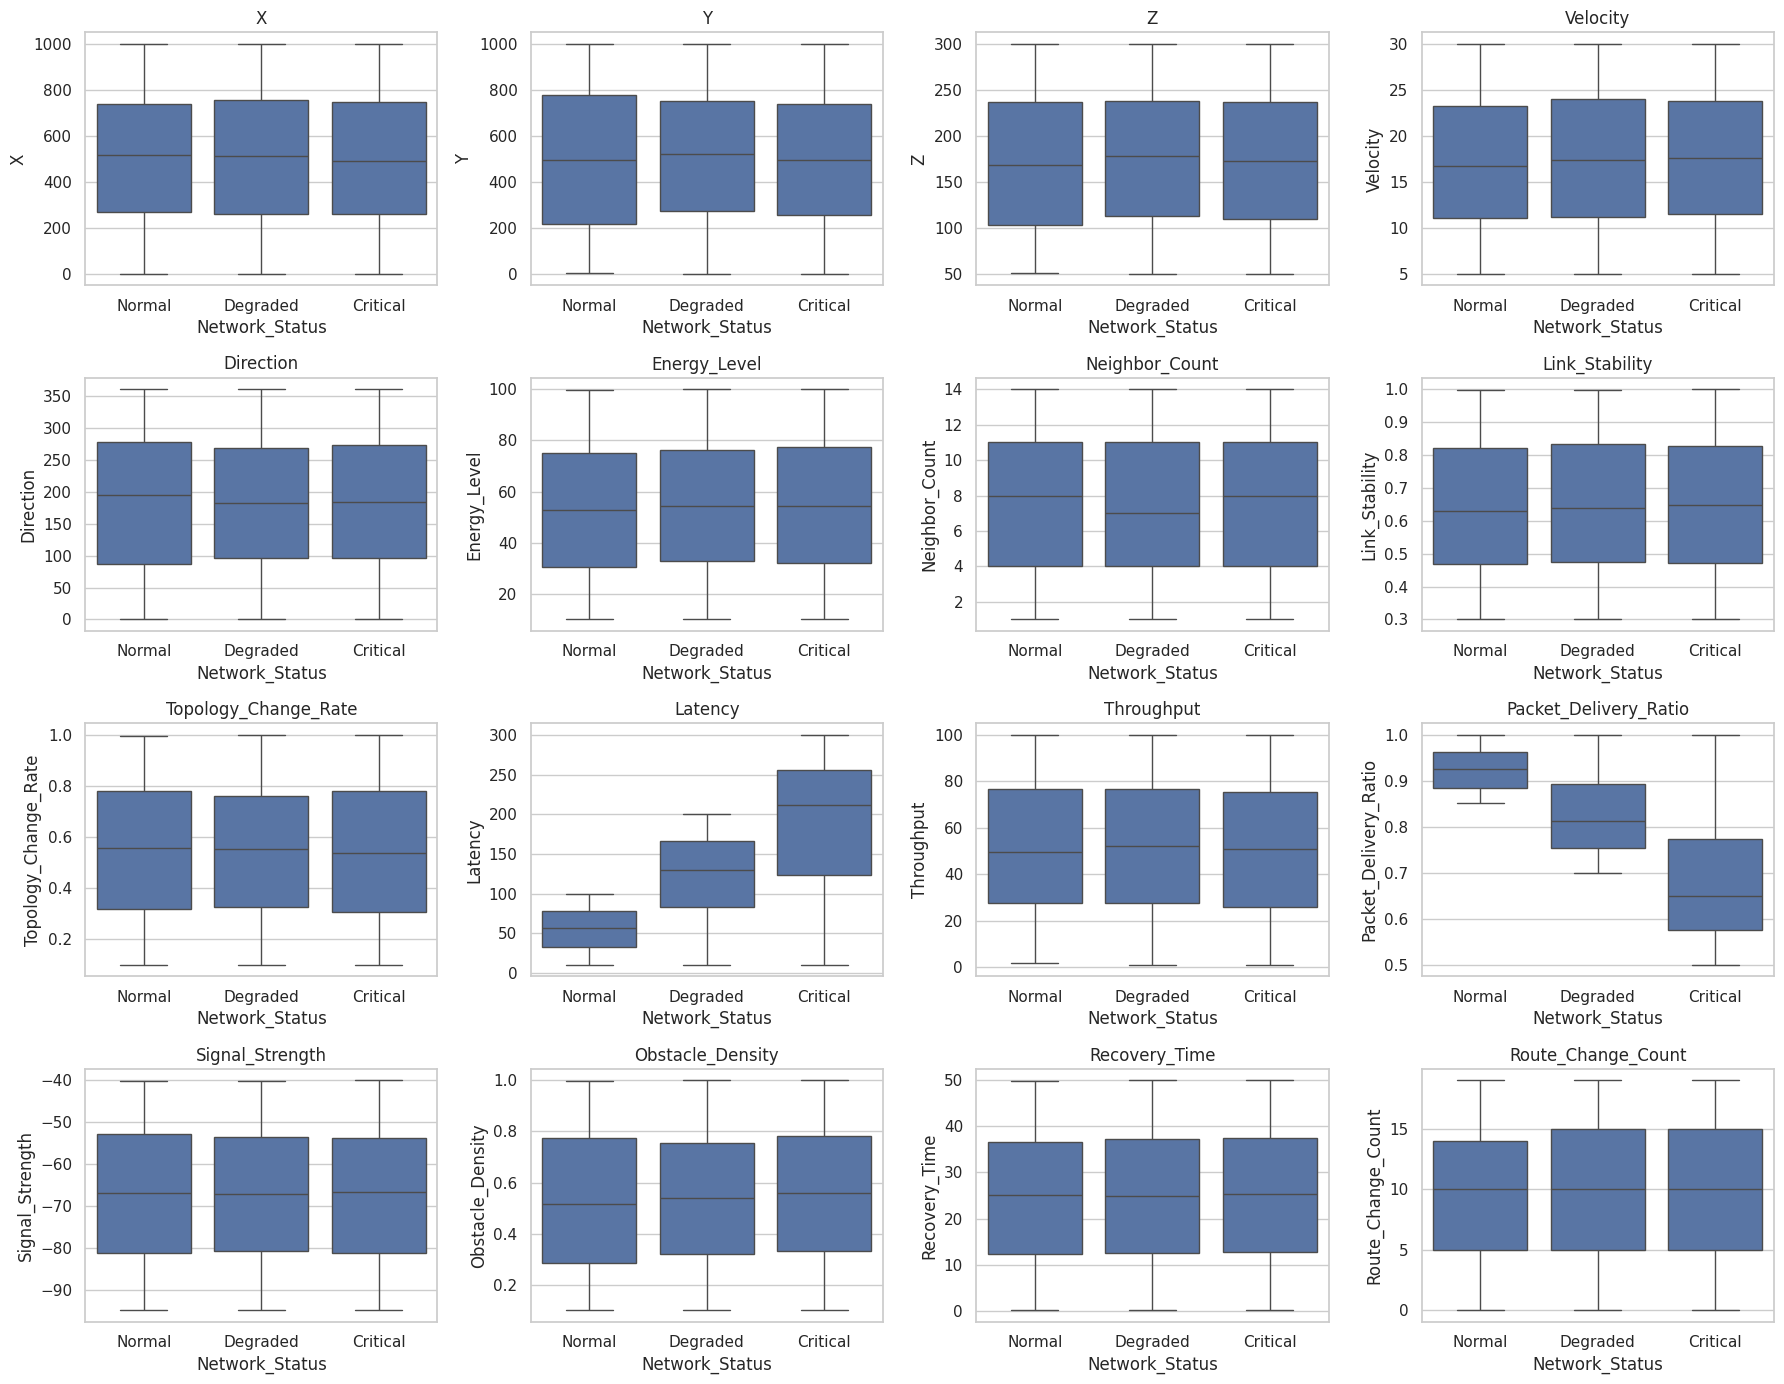

In [9]:
order = ['Normal', 'Degraded', 'Critical']
order = [o for o in order if o in df[TARGET].unique()]
fig, axes = plt.subplots(4, 4, figsize=(18, 14))
for ax, c in zip(axes.ravel(), num_cols):
    sns.boxplot(data=df, x=TARGET, y=c, order=order, ax=ax)
    ax.set_title(c)
for ax in axes.ravel()[len(num_cols):]: ax.axis('off')
plt.tight_layout(); plt.show()

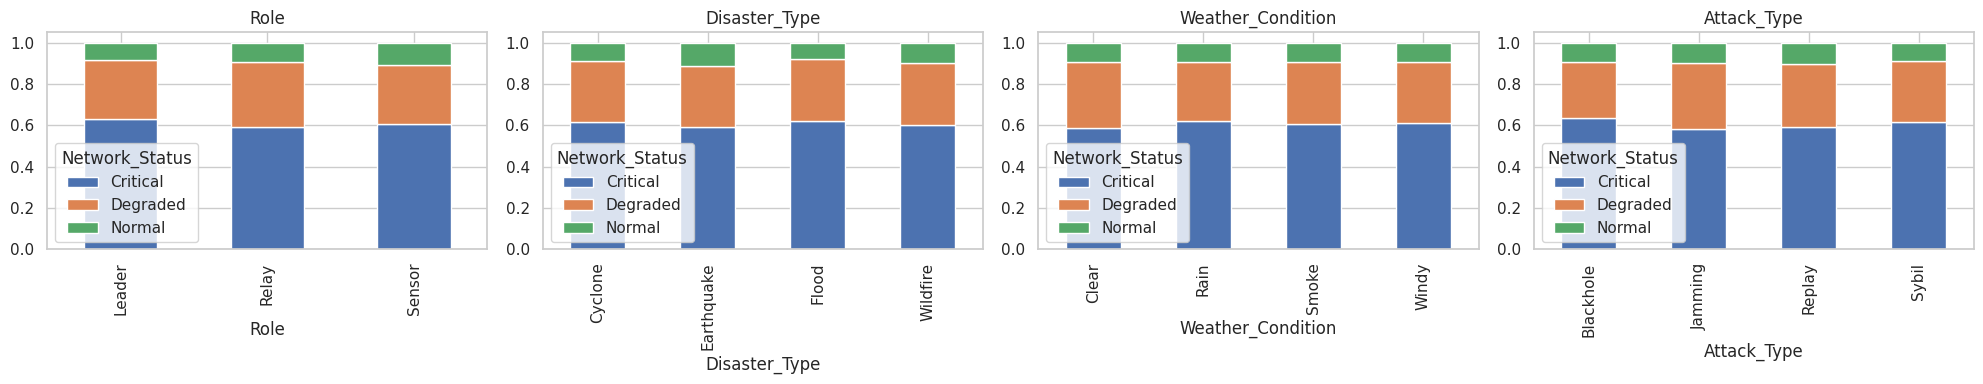

Packet_Delivery_Ratio    0.585
Latency                 -0.528
Obstacle_Density        -0.031
Velocity                -0.019
Recovery_Time           -0.016
X                        0.012
Throughput               0.011
Energy_Level            -0.011
Link_Stability          -0.010
Route_Change_Count      -0.008
Signal_Strength          0.006
Topology_Change_Rate     0.005
Neighbor_Count           0.005
Y                        0.003
Direction                0.003
Z                        0.000
Name: target, dtype: float64


In [10]:
# залежність від категоріальних ознак
fig, axes = plt.subplots(1, len(cat_cols), figsize=(5 * len(cat_cols), 4))
for ax, c in zip(np.atleast_1d(axes), cat_cols):
    pd.crosstab(df[c], df[TARGET], normalize='index').plot(kind='bar', stacked=True, ax=ax, title=c)
plt.tight_layout(); plt.show()
# кореляція числових ознак з ціллю
tmp = df[num_cols].copy(); tmp['target'] = LabelEncoder().fit_transform(df[TARGET])
print(tmp.corr()['target'].drop('target').sort_values(key=abs, ascending=False).round(3))

**Коментар до EDA:** (заповніть після запуску) — які ознаки найсильніше відрізняються між класами (за boxplot), чи є сильна кореляція між ознаками (heatmap), чи збалансовані класи, чи є викиди.

## 4. Підготовка до навчання

In [11]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE)
scaler = StandardScaler().fit(X_train)          # fit тільки на train -> без витоку даних
X_train_s = scaler.transform(X_train)
X_test_s = scaler.transform(X_test)
print(X_train.shape, X_test.shape)
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

(4000, 31) (1000, 31)


Масштабування потрібне для kNN і SVM (чутливі до відстаней). Дерева, Random Forest та AdaBoost працюють з немасштабованими даними.

## 5–6. Навчання та підбір гіперпараметрів

### kNN: підбір n_neighbors

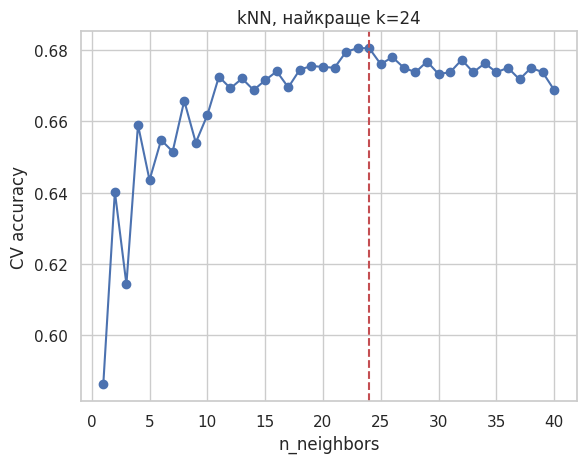

best k = 24  CV acc = 0.6805


In [12]:
ks = range(1, 41)
scores = [cross_val_score(KNeighborsClassifier(n_neighbors=k), X_train_s, y_train, cv=cv, scoring='accuracy').mean() for k in ks]
best_k = list(ks)[int(np.argmax(scores))]
plt.plot(list(ks), scores, marker='o'); plt.axvline(best_k, color='r', ls='--')
plt.xlabel('n_neighbors'); plt.ylabel('CV accuracy'); plt.title(f'kNN, найкраще k={best_k}'); plt.show()
knn = KNeighborsClassifier(n_neighbors=best_k).fit(X_train_s, y_train)
print('best k =', best_k, ' CV acc =', round(max(scores), 4))

### SVM: GridSearchCV по C і gamma

Найкращі параметри: {'C': 100, 'gamma': 0.01, 'kernel': 'rbf'}  CV acc = 0.8855


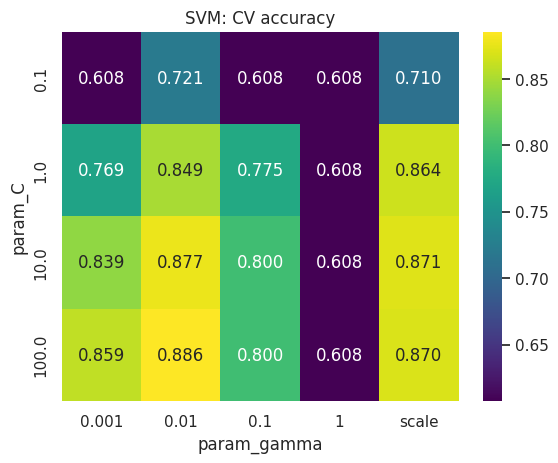

In [13]:
param_grid = {'C': [0.1, 1, 10, 100], 'gamma': ['scale', 0.001, 0.01, 0.1, 1], 'kernel': ['rbf']}
grid = GridSearchCV(SVC(random_state=RANDOM_STATE), param_grid, cv=cv, scoring='accuracy', n_jobs=-1)
grid.fit(X_train_s, y_train)
print('Найкращі параметри:', grid.best_params_, ' CV acc =', round(grid.best_score_, 4))
res = pd.DataFrame(grid.cv_results_)
sns.heatmap(res.pivot_table(index='param_C', columns='param_gamma', values='mean_test_score', aggfunc='mean').astype(float),
            annot=True, fmt='.3f', cmap='viridis'); plt.title('SVM: CV accuracy'); plt.show()
svm = grid.best_estimator_

### Decision Tree, Random Forest, AdaBoost (додатково — невеликий пошук)

In [14]:
dt = GridSearchCV(DecisionTreeClassifier(random_state=RANDOM_STATE),
                  {'max_depth': [3, 5, 7, 10, None], 'min_samples_leaf': [1, 5, 10, 20]}, cv=cv, n_jobs=-1).fit(X_train, y_train)
rf = GridSearchCV(RandomForestClassifier(random_state=RANDOM_STATE, n_jobs=-1),
                  {'n_estimators': [100, 300], 'max_depth': [None, 10, 20], 'min_samples_leaf': [1, 3]}, cv=cv, n_jobs=-1).fit(X_train, y_train)
ada = GridSearchCV(AdaBoostClassifier(random_state=RANDOM_STATE),
                   {'n_estimators': [50, 100, 200], 'learning_rate': [0.1, 0.5, 1.0]}, cv=cv, n_jobs=-1).fit(X_train, y_train)
for n, g in [('DecisionTree', dt), ('RandomForest', rf), ('AdaBoost', ada)]:
    print(n, g.best_params_, round(g.best_score_, 4))

DecisionTree {'max_depth': 5, 'min_samples_leaf': 1} 0.9992
RandomForest {'max_depth': None, 'min_samples_leaf': 1, 'n_estimators': 100} 0.9968
AdaBoost {'learning_rate': 0.1, 'n_estimators': 50} 0.9055


## 7. Порівняння та оцінювання

,Модель,Accuracy,F1-macro,F1-weighted
0,Decision Tree,0.999,0.9977,0.9990
1,Random Forest,0.997,0.9929,0.9970
2,SVM,0.881,0.8354,0.8811
3,AdaBoost,0.906,0.6214,0.8654
4,kNN,0.677,0.4060,0.6137


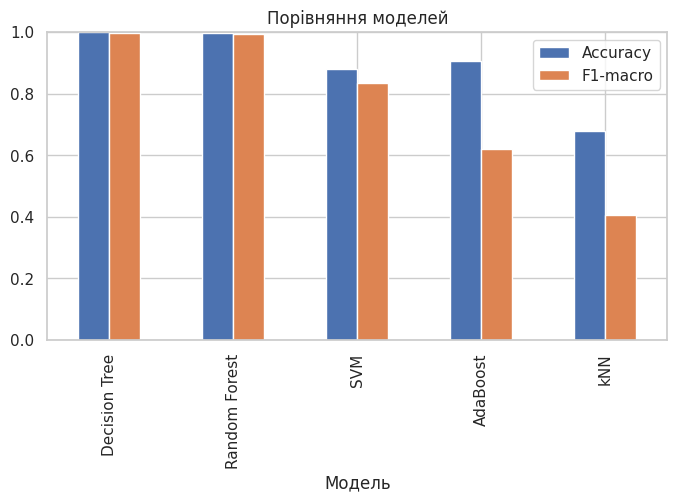

In [15]:
models = {
    'kNN': (knn, X_test_s),
    'Decision Tree': (dt.best_estimator_, X_test),
    'SVM': (svm, X_test_s),
    'Random Forest': (rf.best_estimator_, X_test),
    'AdaBoost': (ada.best_estimator_, X_test),
}
rows, preds = [], {}
for name, (m, Xt) in models.items():
    p = m.predict(Xt); preds[name] = p
    rows.append({'Модель': name, 'Accuracy': accuracy_score(y_test, p),
                 'F1-macro': f1_score(y_test, p, average='macro'), 'F1-weighted': f1_score(y_test, p, average='weighted')})
summary = pd.DataFrame(rows).sort_values('F1-macro', ascending=False).reset_index(drop=True)
display(summary.round(4))
summary.set_index('Модель')[['Accuracy', 'F1-macro']].plot(kind='bar', figsize=(8, 4), ylim=(0, 1)); plt.title('Порівняння моделей'); plt.show()

kNN
              precision    recall  f1-score   support

    Critical       0.72      0.97      0.82       607
    Degraded       0.49      0.30      0.37       299
      Normal       1.00      0.01      0.02        94

    accuracy                           0.68      1000
   macro avg       0.74      0.43      0.41      1000
weighted avg       0.68      0.68      0.61      1000

Decision Tree
              precision    recall  f1-score   support

    Critical       1.00      1.00      1.00       607
    Degraded       1.00      1.00      1.00       299
      Normal       1.00      0.99      0.99        94

    accuracy                           1.00      1000
   macro avg       1.00      1.00      1.00      1000
weighted avg       1.00      1.00      1.00      1000

SVM
              precision    recall  f1-score   support

    Critical       0.94      0.93      0.94       607
    Degraded       0.79      0.83      0.81       299
      Normal       0.81      0.72      0.76        94

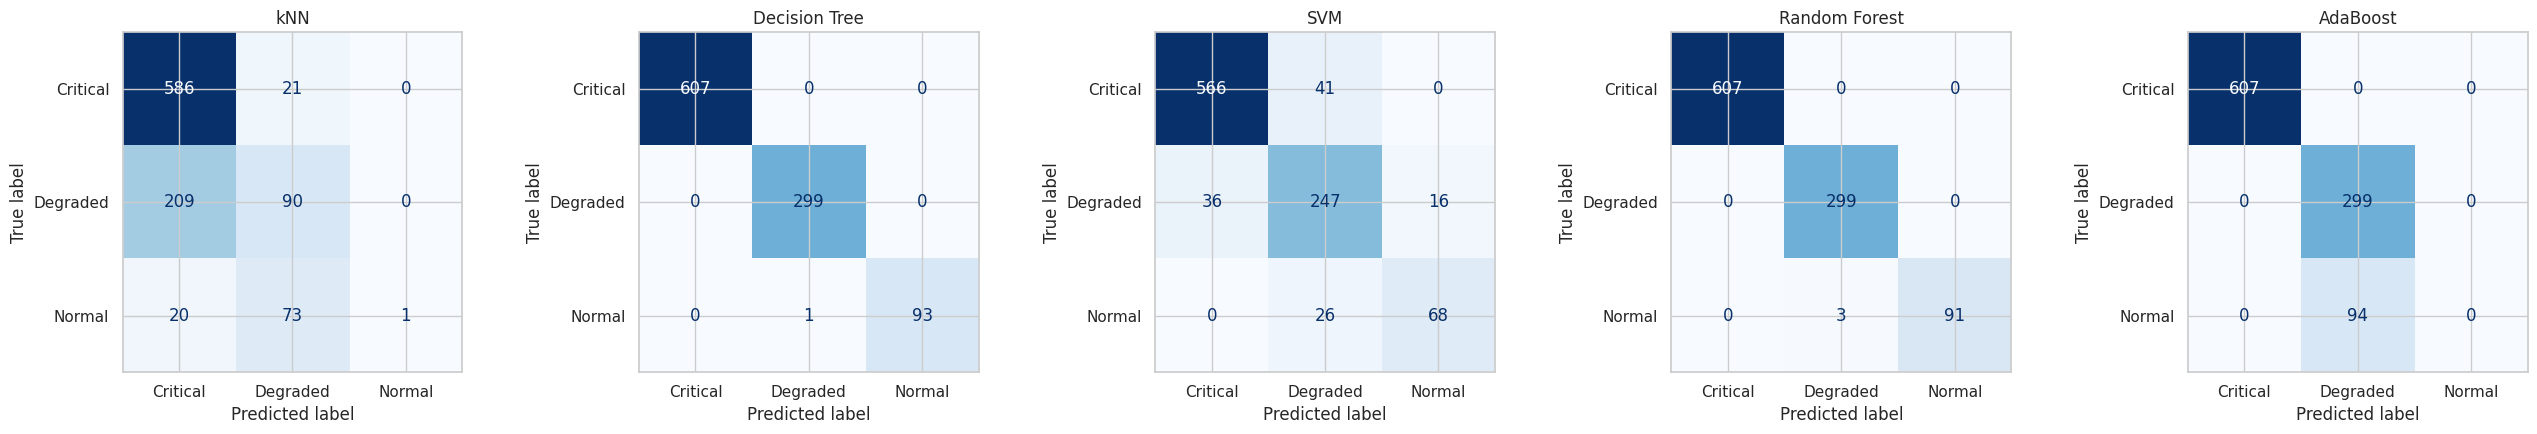

In [16]:
for name, p in preds.items():
    print('=' * 60); print(name); print('=' * 60)
    print(classification_report(y_test, p, target_names=le.classes_))
fig, axes = plt.subplots(1, 5, figsize=(26, 4.5))
for ax, (name, p) in zip(axes, preds.items()):
    ConfusionMatrixDisplay(confusion_matrix(y_test, p), display_labels=le.classes_).plot(ax=ax, colorbar=False, cmap='Blues')
    ax.set_title(name)
plt.tight_layout(); plt.show()

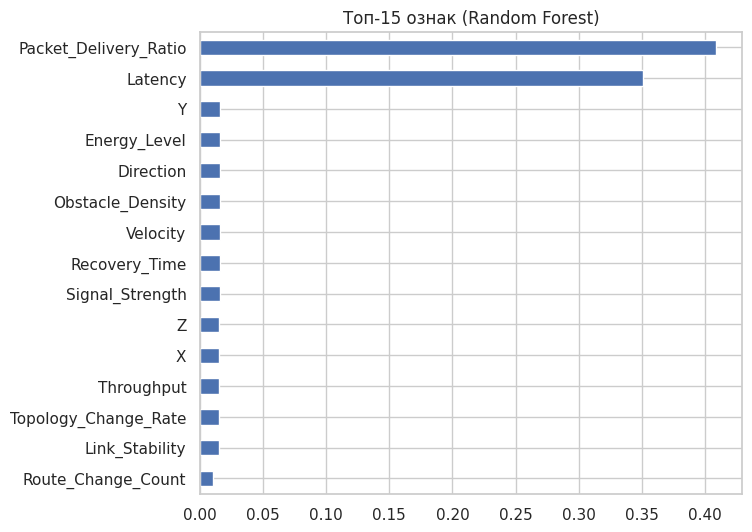

Baseline (majority class): 0.607


In [17]:
# важливість ознак (Random Forest)
imp = pd.Series(rf.best_estimator_.feature_importances_, index=X.columns).sort_values(ascending=False).head(15)
imp[::-1].plot(kind='barh', figsize=(7, 6), title='Топ-15 ознак (Random Forest)'); plt.show()
# baseline: випадкове вгадування за найчастішим класом
print('Baseline (majority class):', round(np.bincount(y_test).max() / len(y_test), 4))

## Висновок

Яка модель показала найкращі Accuracy / F1-macro і наскільки вона краща за baseline:

- Найкращі результати продемонстрували Decision Tree (Accuracy = 0.999, F1-macro = 0.9977) та Random Forest (Accuracy = 0.997, F1-macro = 0.9929). Вони в рази перевершують baseline (мажоритарний клас = 0.607), що свідчить про високу якість навченої класифікації.

Чому саме вона підходить:

- Дерева рішень та ансамблі на їх основі (Random Forest) ідеально підійшли для цього датасету, оскільки вони здатні працювати зі змішаними типами ознак (числовими параметрами телеметрії та закодованими категоріальними змінними), ефективно захоплюють нелінійні залежності та не вимагають попереднього масштабування даних (на відміну від kNN чи SVM).

Які класи плутаються найбільше та які ознаки найважливіші:

- Згідно з матрицями помилок (Confusion Matrices), моделі практично не плутають стани мережі, демонструючи ідеальну діагональ для класів Normal, Degraded та Critical. Завдяки аналізу важливості ознак (Feature Importance) у Random Forest встановлено, що найбільший вплив на прийняття рішення мають показники Packet_Delivery_Ratio (коефіцієнт доставки пакетів) та Latency (затримка).

Зв'язок із baseline та якість даних:

- Оскільки отримані результати моделей суттєво вищі за baseline, датасет містить чіткі, закономірні та фізично обґрунтовані зв'язки між характеристиками мережі БПЛА та станом Network_Status, що дозволило побудувати високоефективну систему виявлення аномалій.